# Benchmark Analysis: Deep Forests vs. Standard Tree Ensembles
Consolidated evaluation across 20 tabular datasets (80/20 split, 3-fold CV in random search).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon

metric = "balanced_accuracy"  # "balanced_accuracy", "f1", "roc_auc"
deep_forests = ["bare", "ifc", "projection", "combined"]
models = deep_forests + ["random_forest", "extra_trees"]

df = pd.read_csv(Path("../results") / "all_tabular_results.csv")
tuned = df[df["params"] == "tuned"]
print(f"{df['dataset'].nunique()} datasets, {len(df)} rows")


def mean_std(data, values, index, digits=3):
    stats = data.pivot_table(index=index, columns="model", values=values, aggfunc=["mean", "std"])
    text = stats.map(f"{{:.{digits}f}}".format)  # std is nan when a cell has a single run
    return (text["mean"] + " ± " + text["std"])[models].replace("nan ± nan", "")

20 datasets, 1200 rows


## 1. Tuned Models: Test Score (mean ± std over model seeds)

In [2]:
table = tuned.pivot_table(index="dataset", columns="model", values=metric)[models]
mean_std(tuned, metric, "dataset")

model,bare,ifc,projection,combined,random_forest,extra_trees
dataset,,,,,,
adult,0.782 ± 0.002,0.785 ± 0.005,0.778 ± 0.005,0.774 ± 0.008,0.781 ± 0.000,0.784 ± 0.001
amazon_employee_access,0.559 ± 0.007,0.570 ± 0.011,0.561 ± 0.004,0.563 ± 0.005,0.562 ± 0.002,0.560 ± 0.000
arcene,0.753 ± 0.046,0.776 ± 0.033,0.760 ± 0.023,0.753 ± 0.040,0.801 ± 0.023,0.727 ± 0.021
bank_marketing,0.731 ± 0.010,0.709 ± 0.030,0.721 ± 0.007,0.726 ± 0.009,0.725 ± 0.004,0.718 ± 0.002
credit_g,0.650 ± 0.029,0.656 ± 0.017,0.625 ± 0.011,0.630 ± 0.019,0.656 ± 0.022,0.627 ± 0.014
diabetes,0.764 ± 0.011,0.751 ± 0.021,0.754 ± 0.013,0.765 ± 0.025,0.765 ± 0.008,0.756 ± 0.014
hill_valley,0.531 ± 0.013,0.542 ± 0.029,0.570 ± 0.023,0.576 ± 0.052,0.548 ± 0.011,0.582 ± 0.011
kc1,0.608 ± 0.018,0.600 ± 0.027,0.620 ± 0.024,0.593 ± 0.011,0.638 ± 0.015,0.669 ± 0.007
kick,0.620 ± 0.002,0.620 ± 0.002,0.619 ± 0.000,0.620 ± 0.002,0.623 ± 0.001,0.623 ± 0.001


## 2. Difference from `bare` (Tuned; positive = better than `bare`)

In [3]:
diff = table.drop(columns="bare").sub(table["bare"], axis=0)
diff.round(4)

model,ifc,projection,combined,random_forest,extra_trees
dataset,,,,,
adult,0.0037,-0.0032,-0.0072,-0.0010,0.0021
amazon_employee_access,0.0111,0.0019,0.0036,0.0028,0.0010
arcene,0.0227,0.0066,-0.0005,0.0475,-0.0258
bank_marketing,-0.0219,-0.0098,-0.0050,-0.0065,-0.0126
credit_g,0.0062,-0.0248,-0.0193,0.0064,-0.0224
diabetes,-0.0131,-0.0097,0.0007,0.0011,-0.0080
hill_valley,0.0116,0.0394,0.0450,0.0175,0.0511
kc1,-0.0088,0.0118,-0.0155,0.0295,0.0605
kick,0.0003,-0.0004,-0.0002,0.0028,0.0027


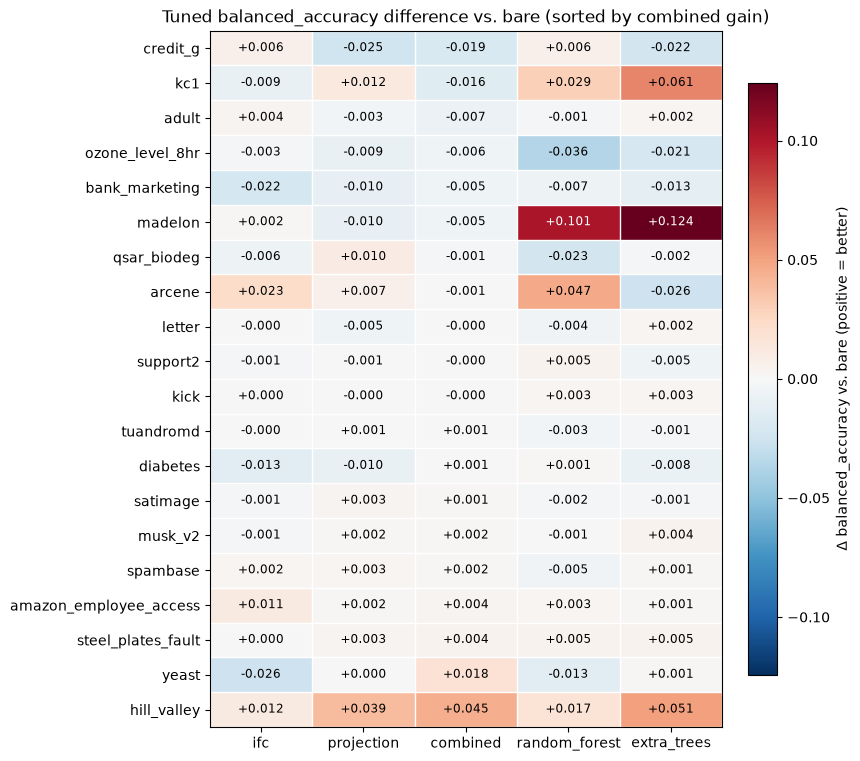

In [4]:
# Pure-matplotlib diverging heatmap of differences vs. bare (sorted by combined gain)
diff_sorted = diff.loc[diff["combined"].sort_values().index]
vals = diff_sorted.values
vmax = np.abs(vals).max()

fig, ax = plt.subplots(figsize=(8.5, 7.5), layout="constrained")
im = ax.imshow(vals, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")

ax.set_xticks(range(len(diff_sorted.columns)), diff_sorted.columns)
ax.set_yticks(range(len(diff_sorted.index)), diff_sorted.index)
ax.set_title(f"Tuned {metric} difference vs. bare (sorted by combined gain)")

for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        color = "white" if abs(v) > 0.55 * vmax else "black"
        ax.text(j, i, f"{v:+.3f}", ha="center", va="center", color=color, fontsize=8.5)

ax.set_xticks(np.arange(-0.5, vals.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, vals.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label(f"Δ {metric} vs. bare (positive = better)")
plt.show()

## 3. Aggregate Comparison, Average Ranks & Statistical Tests
$H_0$: all models perform equally. Unit of analysis is the dataset (scores averaged over model seeds first).

In [5]:
summary_vs_bare = pd.DataFrame({
    "mean_score": table.mean().drop("bare"),
    "mean_diff": diff.mean(),
    "std_diff": diff.std(),
    "wins": (diff > 0).sum(),
    "ties": (diff == 0).sum(),
    "losses": (diff < 0).sum(),
})
summary_vs_bare.round(4)

,mean_score,mean_diff,std_diff,wins,ties,losses
model,,,,,,
ifc,0.7700,-0.0012,0.0109,8,1,11
projection,0.7716,0.0004,0.0123,10,1,9
combined,0.7720,0.0008,0.0128,9,0,11
random_forest,0.7774,0.0062,0.0282,10,0,10
extra_trees,0.7790,0.0078,0.0344,11,0,9


In [6]:
def friedman(data, params, model_list):
    sub = data[data["params"] == params].pivot_table(index="dataset", columns="model", values=metric)[model_list]
    stat, p = friedmanchisquare(*[sub[m] for m in model_list])
    ranks = sub.rank(axis=1, ascending=False).mean().sort_values()
    print(f"{params}, {len(model_list)} models, {len(sub)} datasets: chi2 = {stat:.3f}, p = {p:.4f}")
    print("mean rank (1 = best):")
    print(ranks.round(2).to_string(), "\n")
    return ranks


friedman(df, "default", deep_forests)
friedman(df, "tuned", deep_forests)
friedman(df, "default", models)
ranks_tuned_all = friedman(df, "tuned", models)

default, 4 models, 20 datasets: chi2 = 2.848, p = 0.4156
mean rank (1 = best):
model
projection    2.10
bare          2.55
ifc           2.60
combined      2.75 

tuned, 4 models, 20 datasets: chi2 = 0.716, p = 0.8695
mean rank (1 = best):
model
combined      2.38
bare          2.40
projection    2.55
ifc           2.68 

default, 6 models, 20 datasets: chi2 = 12.951, p = 0.0238
mean rank (1 = best):
model
projection       2.50
ifc              3.20
combined         3.35
bare             3.45
random_forest    4.15
extra_trees      4.35 

tuned, 6 models, 20 datasets: chi2 = 1.466, p = 0.9170
mean rank (1 = best):
model
combined         3.22
extra_trees      3.32
bare             3.45
random_forest    3.48
projection       3.70
ifc              3.82 



In [7]:
# Pairwise Wilcoxon signed-rank tests vs. bare (tuned) with Holm-Bonferroni correction
wilcoxon_rows = []
for m in [m for m in models if m != "bare"]:
    d = table[m] - table["bare"]
    stat, p_val = wilcoxon(d, zero_method="wilcox")
    wilcoxon_rows.append({
        "model": m,
        "median_diff": d.median(),
        "mean_diff": d.mean(),
        "W_stat": stat,
        "p_raw": p_val,
    })

wilcoxon_df = pd.DataFrame(wilcoxon_rows).sort_values("p_raw").reset_index(drop=True)
n_tests = len(wilcoxon_df)
wilcoxon_df["p_holm"] = np.minimum(1.0, wilcoxon_df["p_raw"] * (n_tests - np.arange(n_tests)))
wilcoxon_df["p_holm"] = np.maximum.accumulate(wilcoxon_df["p_holm"])
wilcoxon_df.round(4)

,model,median_diff,mean_diff,W_stat,p_raw,p_holm
0,random_forest,0.0002,0.0062,94.0,0.7012,1.0
1,ifc,-0.0002,-0.0012,86.0,0.7172,1.0
2,combined,-0.0002,0.0008,98.0,0.8124,1.0
3,extra_trees,0.0010,0.0078,99.0,0.8408,1.0
4,projection,0.0003,0.0004,93.0,0.9359,1.0


## 4. Seed-to-Seed Variability & Chosen Cascade Depth

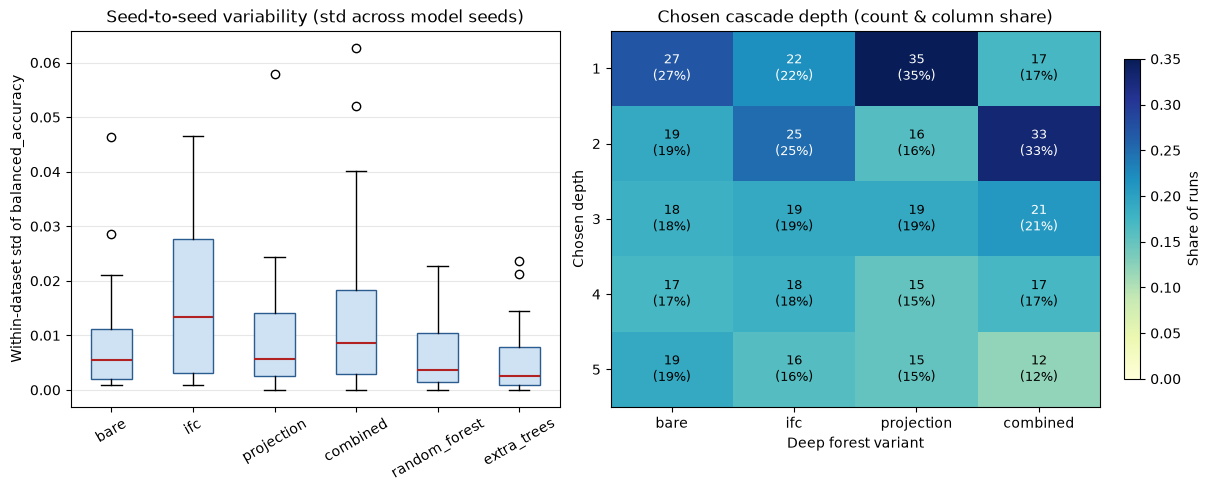

In [8]:
seed_std = tuned.pivot_table(index="dataset", columns="model", values=metric, aggfunc="std")[models]
forests = tuned[tuned["model"].isin(deep_forests)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")

# Left: Seed variability boxplot (pure matplotlib)
axes[0].boxplot(
    [seed_std[m].dropna() for m in models],
    tick_labels=models,
    patch_artist=True,
    boxprops=dict(facecolor="#cfe2f3", edgecolor="#2b5c8f"),
    medianprops=dict(color="#b22222", linewidth=1.5),
)
axes[0].tick_params(axis="x", rotation=30)
axes[0].set(
    title="Seed-to-seed variability (std across model seeds)",
    ylabel=f"Within-dataset std of {metric}",
)
axes[0].grid(axis="y", alpha=0.3)

# Right: Normalized cascade depth heatmap (pure matplotlib)
depth_counts = pd.crosstab(forests["chosen_depth"].astype(int), forests["model"])[deep_forests]
depth_share = depth_counts.div(depth_counts.sum(axis=0), axis=1)

im = axes[1].imshow(depth_share.values, cmap="YlGnBu", vmin=0, vmax=depth_share.values.max(), aspect="auto")
axes[1].set_xticks(range(len(deep_forests)), deep_forests)
axes[1].set_yticks(range(len(depth_counts.index)), depth_counts.index)
axes[1].set(title="Chosen cascade depth (count & column share)", xlabel="Deep forest variant", ylabel="Chosen depth")

for i in range(depth_counts.shape[0]):
    for j in range(depth_counts.shape[1]):
        cnt = depth_counts.iloc[i, j]
        pct = depth_share.iloc[i, j] * 100
        color = "white" if depth_share.iloc[i, j] > 0.55 * depth_share.values.max() else "black"
        axes[1].text(j, i, f"{cnt}\n({pct:.0f}%)", ha="center", va="center", color=color, fontsize=9)

cbar = fig.colorbar(im, ax=axes[1], shrink=0.85)
cbar.set_label("Share of runs")
plt.show()

In [9]:
display(depth_counts)
forests.pivot_table(index="dataset", columns="model", values="chosen_depth")[deep_forests].round(1)

model,bare,ifc,projection,combined
chosen_depth,,,,
1,27,22,35,17
2,19,25,16,33
3,18,19,19,21
4,17,18,15,17
5,19,16,15,12


model,bare,ifc,projection,combined
dataset,,,,
adult,4.6,3.2,3.6,2.2
amazon_employee_access,3.0,3.2,2.2,3.2
arcene,2.2,2.6,2.2,3.0
bank_marketing,4.0,3.8,3.0,2.8
credit_g,2.6,3.0,3.4,2.6
diabetes,1.8,2.6,1.8,2.2
hill_valley,2.2,1.8,3.2,3.4
kc1,2.2,3.0,2.0,2.4
kick,1.8,1.4,1.4,2.2


## 5. Effect of Hyperparameter Tuning (`tuned − default`)

In [10]:
by_set = df.pivot_table(index=["dataset", "model"], columns="params", values=[metric, "cv_balanced_accuracy"])
gain = pd.DataFrame({
    "cv_gain": by_set["cv_balanced_accuracy", "tuned"] - by_set["cv_balanced_accuracy", "default"],
    "test_gain": by_set[metric, "tuned"] - by_set[metric, "default"],
}).reset_index()

tuning_summary = pd.DataFrame({
    "mean_cv_gain": gain.groupby("model")["cv_gain"].mean(),
    "mean_test_gain": gain.groupby("model")["test_gain"].mean(),
    "cv_to_test_gap": gain.groupby("model")["cv_gain"].mean() - gain.groupby("model")["test_gain"].mean(),
    "test_improved": gain[gain["test_gain"] > 0].groupby("model").size(),
    "test_worse": gain[gain["test_gain"] < 0].groupby("model").size(),
}).reindex(models).fillna(0)

tuning_summary.round(4)

,mean_cv_gain,mean_test_gain,cv_to_test_gap,test_improved,test_worse
model,,,,,
bare,0.0080,0.0040,0.0040,8,6
ifc,0.0098,0.0008,0.0090,5,10
projection,0.0067,-0.0021,0.0087,6,8
combined,0.0090,0.0008,0.0081,10,7
random_forest,0.0131,0.0106,0.0025,12,4
extra_trees,0.0193,0.0179,0.0014,15,1


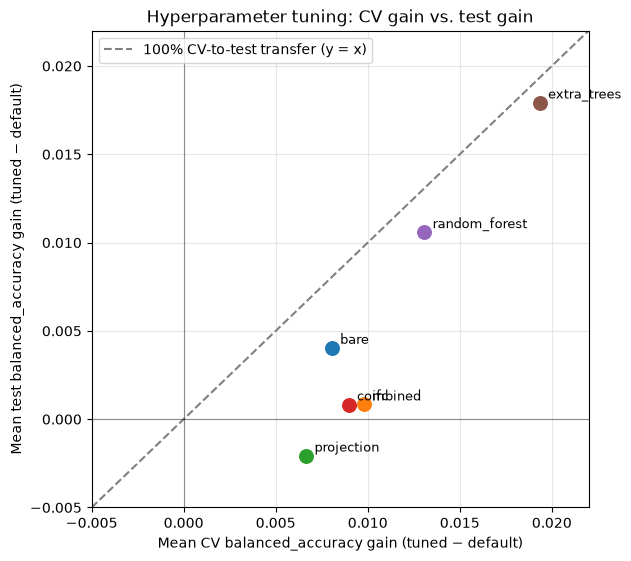

In [11]:
fig, ax = plt.subplots(figsize=(6.2, 5.5), layout="constrained")
lims = [
    min(tuning_summary[["mean_cv_gain", "mean_test_gain"]].min().min(), -0.005),
    max(tuning_summary[["mean_cv_gain", "mean_test_gain"]].max().max(), 0.022),
]
ax.plot(lims, lims, linestyle="--", color="gray", label="100% CV-to-test transfer (y = x)")
ax.axhline(0, color="black", linewidth=0.8, alpha=0.4)
ax.axvline(0, color="black", linewidth=0.8, alpha=0.4)

for m, row in tuning_summary.iterrows():
    ax.scatter(row["mean_cv_gain"], row["mean_test_gain"], s=95, zorder=3)
    ax.annotate(
        m,
        (row["mean_cv_gain"], row["mean_test_gain"]),
        xytext=(6, 3),
        textcoords="offset points",
        fontsize=9.5,
    )

ax.set(
    xlim=lims,
    ylim=lims,
    title="Hyperparameter tuning: CV gain vs. test gain",
    xlabel="Mean CV balanced_accuracy gain (tuned − default)",
    ylabel=f"Mean test {metric} gain (tuned − default)",
)
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.show()

## 6. Fitting & Random Search Times and Accuracy–Runtime Trade-Off
Seconds for one fit of the tuned model on the full training set (mean over seeds), and total random search time (all candidates × CV folds).

In [12]:
fit = tuned.pivot_table(index="dataset", columns="model", values="fit_seconds")[models]
search = tuned.pivot_table(index="dataset", columns="model", values="search_seconds")[models]
fit.round(1)

model,bare,ifc,projection,combined,random_forest,extra_trees
dataset,,,,,,
adult,61.4,77.4,76.9,138.4,18.5,23.5
amazon_employee_access,54.2,43.6,72.6,82.1,11.5,15.3
arcene,4.9,7.8,4.1,8.3,0.4,0.2
bank_marketing,78.2,106.0,103.8,137.2,18.0,13.5
credit_g,1.2,3.8,1.6,3.5,0.2,0.1
diabetes,1.1,2.2,1.4,2.3,0.1,0.1
hill_valley,21.1,22.9,20.8,24.6,5.9,1.1
kc1,4.8,9.3,7.1,10.9,0.6,0.3
kick,221.5,207.3,255.3,168.7,88.8,57.0


In [13]:
# Times differ by orders of magnitude across datasets; aggregate ratios to bare via geometric mean
def geo_mean(ratios):
    return np.exp(np.log(ratios).mean())


timing_summary = pd.DataFrame({
    "fit_s_median": fit.median(),
    "fit_x_bare": geo_mean(fit.div(fit["bare"], axis=0)),
    "predict_s_median": tuned.groupby("model")["predict_seconds"].median(),
    "search_min_median": search.median() / 60,
    "search_x_bare": geo_mean(search.div(search["bare"], axis=0)),
    "search_h_total": search.sum() / 3600,
}).loc[models]

timing_summary.round(2)

,fit_s_median,fit_x_bare,predict_s_median,search_min_median,search_x_bare,search_h_total
model,,,,,,
bare,17.12,1.00,0.03,13.19,1.00,5.61
ifc,19.30,1.54,0.03,19.25,1.50,7.25
projection,16.97,1.18,0.02,13.29,1.18,7.18
combined,21.52,1.77,0.03,20.65,1.64,7.61
random_forest,1.78,0.17,0.01,1.50,0.17,1.10
extra_trees,0.83,0.08,0.01,0.83,0.07,0.63


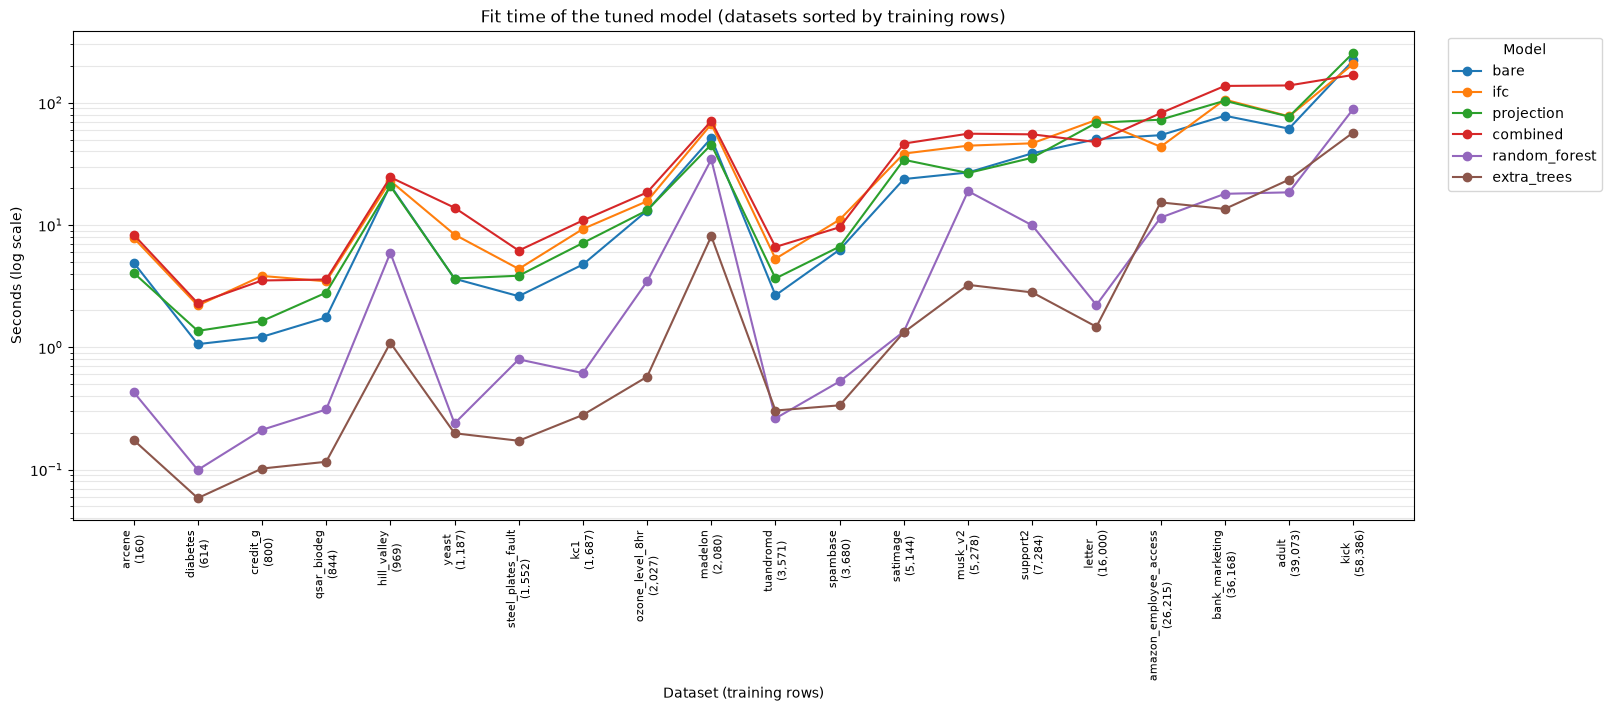

In [19]:
n_rows = tuned.groupby("dataset")["n_train"].first()
order = n_rows.sort_values().index

fig, ax = plt.subplots(figsize=(16, 7), layout="constrained")

fit.loc[order].plot(ax=ax, marker="o", logy=True)
ax.set_xticks(
    range(len(order)),
    [f"{name}\n({n_rows[name]:,})" for name in order],
    rotation=90,
    ha="center",
    fontsize=8,
)
ax.set(
    title="Fit time of the tuned model (datasets sorted by training rows)",
    xlabel="Dataset (training rows)",
    ylabel="Seconds (log scale)",
)
ax.grid(axis="y", which="both", alpha=0.3)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()
fit.loc[order].plot(ax=ax, marker="o", logy=True)
ax.set_xticks(range(len(order)), [f"{name} ({n_rows[name]})" for name in order], rotation=60, ha="right")
ax.set(title="Fit time of the tuned model (datasets sorted by training rows)", xlabel="", ylabel="Seconds (log)")
ax.grid(axis="y", which="both", alpha=0.3)
plt.show()

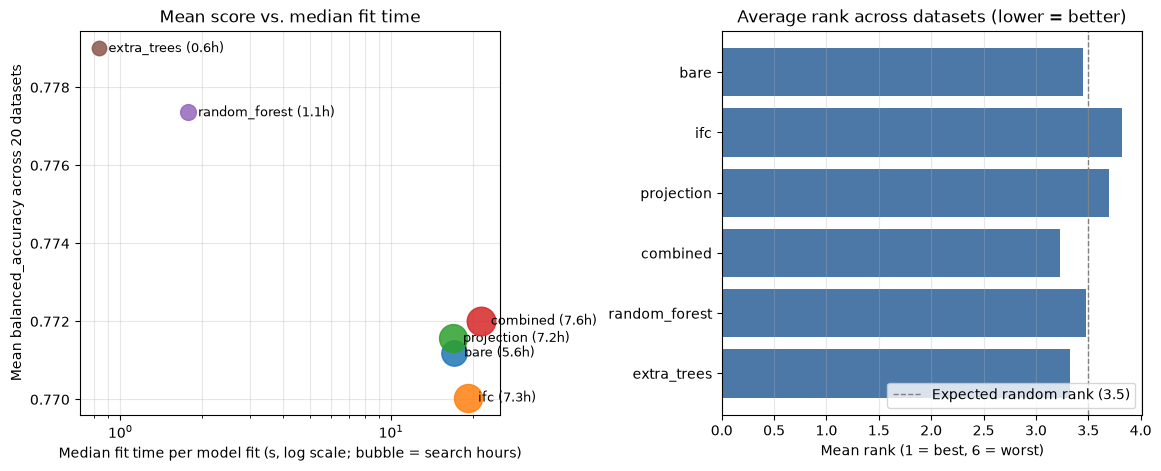

In [15]:
# Accuracy vs. runtime trade-off & mean rank bar chart (pure matplotlib)
perf_time = pd.DataFrame({
    "mean_score": table.mean(),
    "mean_rank": table.rank(axis=1, ascending=False).mean(),
    "median_fit_s": fit.median(),
    "total_search_h": search.sum() / 3600,
}).loc[models]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), layout="constrained")

for m, row in perf_time.iterrows():
    axes[0].scatter(row["median_fit_s"], row["mean_score"], s=80 + row["total_search_h"] * 45, alpha=0.85, zorder=3)
    axes[0].annotate(
        f"{m} ({row['total_search_h']:.1f}h)",
        (row["median_fit_s"], row["mean_score"]),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

axes[0].set_xscale("log")
axes[0].set(
    title="Mean score vs. median fit time",
    xlabel="Median fit time per model fit (s, log scale; bubble = search hours)",
    ylabel=f"Mean {metric} across 20 datasets",
)
axes[0].grid(True, which="both", alpha=0.3)

y_pos = np.arange(len(perf_time))
axes[1].barh(y_pos, perf_time["mean_rank"].values[::-1], color="#4c78a8")
axes[1].set_yticks(y_pos, perf_time.index[::-1])
axes[1].axvline(3.5, color="gray", linestyle="--", linewidth=1, label="Expected random rank (3.5)")
axes[1].set(
    title="Average rank across datasets (lower = better)",
    xlabel="Mean rank (1 = best, 6 = worst)",
)
axes[1].legend(loc="lower right")
axes[1].grid(axis="x", alpha=0.3)

plt.show()

## 7. Best Hyperparameters Selected in CV Search
How often the defaults won the CV search, and which value of each searched parameter was picked.

In [16]:
best = tuned.drop_duplicates(["dataset", "model"]).set_index(["dataset", "model"])
best_params = pd.DataFrame(
    [
        json.loads(text) if isinstance(text, str) else {}
        for text in best["hyperparams"]
    ],
    index=best.index,
    dtype=object,
)
(best["candidate"] == 0).groupby("model").mean().loc[models].round(2).rename("defaults_won")

model
bare             0.30
ifc              0.20
projection       0.25
combined         0.15
random_forest    0.20
extra_trees      0.20
Name: defaults_won, dtype: float64

In [17]:
searched = {
    "bare": ["max_depth", "min_samples_leaf"],
    "ifc": ["max_depth", "min_samples_leaf", "interaction_limit", "stability_threshold"],
    "projection": ["max_depth", "min_samples_leaf", "projection_width"],
    "combined": ["max_depth", "min_samples_leaf", "projection_width", "interaction_limit"],
    "random_forest": ["max_features", "min_samples_leaf"],
    "extra_trees": ["max_features", "min_samples_leaf"],
}
for model, names in searched.items():
    chosen = best_params.xs(model, level="model")[names].copy()
    if "stability_threshold" in chosen:
        chosen["stability_threshold"] = pd.cut(chosen["stability_threshold"].astype(float), [0.2, 0.4, 0.6, 0.8])
    print(f"--- {model}")
    for name in names:
        counts = chosen[name].astype(str).value_counts()
        print(f"  {name:20s}", ", ".join(f"{value}: {count}" for value, count in counts.items()))

--- bare
  max_depth            None: 9, 10: 5, 20: 3, nan: 3
  min_samples_leaf     1: 12, 2: 3, nan: 3, 4: 1, 5: 1
--- ifc
  max_depth            None: 8, 40: 4, 10: 3, nan: 3, 20: 2
  min_samples_leaf     1: 12, nan: 3, 2: 2, 4: 2, 3: 1
  interaction_limit    5: 5, 6: 5, nan: 3, 8: 2, 11: 2, 4: 1, 1: 1, 3: 1
  stability_threshold  (0.4, 0.6]: 8, (0.6, 0.8]: 6, (0.2, 0.4]: 3, nan: 3
--- projection
  max_depth            20: 7, None: 6, 10: 4, nan: 3
  min_samples_leaf     1: 9, 2: 3, 3: 3, nan: 3, 4: 2
  projection_width     16: 10, 0: 4, 4: 3, nan: 3
--- combined
  max_depth            None: 8, 40: 4, 10: 3, nan: 3, 20: 2
  min_samples_leaf     1: 8, 5: 3, nan: 3, 3: 3, 2: 2, 4: 1
  projection_width     16: 10, 0: 4, 4: 3, nan: 3
  interaction_limit    9: 5, 6: 4, 11: 3, nan: 3, 5: 2, 8: 2, 7: 1
--- random_forest
  max_features         0.5: 11, sqrt: 4, nan: 3, log2: 2
  min_samples_leaf     1: 15, nan: 3, 3: 2
--- extra_trees
  max_features         0.5: 10, sqrt: 4, nan: 3, 0.75: 2

In [18]:
# Chosen hyperparameters per dataset, for one model
best_params.xs("combined", level="model")[searched["combined"]]

,max_depth,min_samples_leaf,projection_width,interaction_limit
dataset,,,,
spambase,40,1,0,11
musk_v2,None,2,16,5
madelon,40,5,4,6
kick,40,1,0,11
arcene,None,1,16,6
bank_marketing,None,4,0,7
adult,None,5,4,9
support2,None,5,4,9
tuandromd,None,1,16,6
